本 notebook 是 [M01.5 高性能科学 Python](../notes/05-high-performance-python.qmd) 的实例讲解。
贯穿全篇的例子是一个 Lennard-Jones（LJ）体系：$N$ 个原子组成带随机扰动的 fcc 晶格，放在立方周期盒子里
（约化单位，$\sigma = \varepsilon = 1$，数密度 0.8），计算原子对位移、能量和维里应力。内容：

1. strides 与内存布局：视图、拷贝和 `np.shares_memory`；
2. 同样的求和，沿哪个轴做决定了快慢；
3. 广播计算全部原子对的位移：速度与 $(N, N, 3)$ 中间数组的内存代价；
4. `einsum`：一行写出维里应力，以及 `optimize=True` 的作用；
5. 避免隐式拷贝：`out=` 与原地运算；
6. 用 `cProfile` 找到慢函数，用 `line_profiler` 找到慢的那一行；
7. Numba：把双重循环编译成机器码，以及第一次调用的编译开销。

**运行方式**：第 6、7 节需要可选依赖，先在仓库根目录运行 `uv sync --extra perf`。
然后在 VS Code 中打开本文件，选择仓库 `.venv` 的 Python 内核，从上到下运行。
改动代码后可用 `make nb M=01` 重新执行并保存输出。

**关于计时**：下文的绝对时间取决于机器（本文输出来自一台 Apple M4 笔记本），
结论只看相对量：加速倍数和随 $N$ 的增长趋势。每个计时取多次重复中的最小值，
它最接近“没有被其他进程打扰”时的耗时。

In [1]:
import cProfile
import io
import pstats
import timeit
import tracemalloc

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats

from semiai.plotting import BLUE, GRAY, ORANGE, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(0)


def best_time(stmt, number: int = 5, repeat: int = 5) -> float:
    """stmt 单次调用耗时的最小值（秒）：repeat 组、每组 number 次。"""
    return min(timeit.repeat(stmt, number=number, repeat=repeat)) / number

## 1. strides：同一块内存的不同“看法”

一个 NumPy 数组 = 一块连续内存 + 描述如何解释它的元数据（`shape`、`dtype`、`strides`）。
`strides[k]` 是沿第 $k$ 个轴走一步要跨过的字节数
（[讲义的地址公式](../notes/05-high-performance-python.qmd#eq-address)）。
转置、基本切片只改元数据，不复制数据，得到的是**视图**；花式索引（整数数组、布尔掩码）
必须把选中的元素收集到新内存，得到的是**拷贝**。

In [2]:
a = np.arange(12, dtype=np.float64).reshape(3, 4)
views = {
    "a": a,
    "a.T": a.T,
    "a[:, ::2]": a[:, ::2],
    "a[1]": a[1],
    "a[[0, 2]]": a[[0, 2]],
    "a[a > 5]": a[a > 5],
    "np.asfortranarray(a)": np.asfortranarray(a),
}
pd.DataFrame(
    [
        {
            "表达式": name,
            "shape": v.shape,
            "strides（字节）": v.strides,
            "C 连续": v.flags["C_CONTIGUOUS"],
            "F 连续": v.flags["F_CONTIGUOUS"],
            "与 a 共享内存": np.shares_memory(v, a),
        }
        for name, v in views.items()
    ]
).set_index("表达式")

,shape,strides（字节）,C 连续,F 连续,与 a 共享内存
表达式,,,,,
a,"(3, 4)","(32, 8)",True,False,True
a.T,"(4, 3)","(8, 32)",False,True,True
"a[:, ::2]","(3, 2)","(32, 16)",False,False,True
a[1],"(4,)","(8,)",True,True,True
"a[[0, 2]]","(2, 4)","(32, 8)",True,False,False
a[a > 5],"(6,)","(8,)",True,True,False
np.asfortranarray(a),"(3, 4)","(8, 24)",False,True,False


读法：`a` 的 strides 是 `(32, 8)`：同一行相邻元素差 8 字节（一个 float64），换行跨 32 字节（4 个元素）。
`a.T` 只是把 strides 交换成 `(8, 32)`，数据一个字节没动，所以它是 F 连续而不是 C 连续。
`a[:, ::2]` 把列方向的步长翻倍成 16 字节，既不是 C 连续也不是 F 连续。
两个花式索引的结果与 `a` 不共享内存，是拷贝。

视图意味着“改一处，两处都变”。这在 MD 后处理里很常见：从轨迹数组切出一帧再原地平移，原始轨迹也被改了。

In [3]:
traj = rng.random((5, 4, 3))  # (帧, 原子, xyz)
frame = traj[2]  # 基本索引：视图
frame -= frame.mean(axis=0)  # 原地去质心
print("traj[2] 的质心被改成了：", traj[2].mean(axis=0).round(12))

frame_copy = traj[3].copy()  # 显式拷贝才安全
frame_copy -= frame_copy.mean(axis=0)
print("traj[3] 的质心保持不变：", traj[3].mean(axis=0).round(3))

traj[2] 的质心被改成了： [0. 0. 0.]
traj[3] 的质心保持不变： [0.582 0.507 0.568]


## 2. 沿哪个轴求和决定了快慢

对一个 $4000 \times 4000$ 的 C 顺序数组，分别对每一行求和和对每一列求和；再把数组换成 F 顺序重复一次。
计算量完全相同，区别只在访问内存的顺序。为了把“访问顺序”这个因素单独拿出来，这里用纯 Python 的
外层循环逐行（或逐列）调用 `np.sum`：每次调用处理的是一个一维切片，切片连续与否决定了它的快慢。

In [4]:
n = 4000
c_arr = rng.random((n, n))
f_arr = np.asfortranarray(c_arr)


def sum_rows(x: np.ndarray) -> np.ndarray:
    return np.array([x[i, :].sum() for i in range(x.shape[0])])


def sum_cols(x: np.ndarray) -> np.ndarray:
    return np.array([x[:, j].sum() for j in range(x.shape[1])])


assert np.allclose(sum_rows(c_arr), sum_rows(f_arr))
rows = []
for layout, arr in (("C 顺序", c_arr), ("F 顺序", f_arr)):
    t_row = best_time(lambda arr=arr: sum_rows(arr), number=1)
    t_col = best_time(lambda arr=arr: sum_cols(arr), number=1)
    rows.append(
        {
            "布局": layout,
            "逐行求和 (ms)": t_row * 1e3,
            "逐列求和 (ms)": t_col * 1e3,
            "慢 / 快": max(t_row, t_col) / min(t_row, t_col),
        }
    )
pd.DataFrame(rows).set_index("布局").round(2)

,逐行求和 (ms),逐列求和 (ms),慢 / 快
布局,,,
C 顺序,3.46,29.71,8.58
F 顺序,29.58,3.39,8.74


读法：C 顺序数组逐行快、逐列慢；F 顺序数组正好相反。慢的那种情况，每取一个元素都要跨过一整行
（32000 字节），读进缓存的一整条缓存行里只用了 8 字节。缓存行和存储层次的细节见
[M01.4 计算机系统基础](../notes/04-computer-systems.qmd)。

实际写代码时通常不需要这样手写循环：`c_arr.sum(axis=0)` 由 NumPy 内部选择合适的遍历顺序。
但只要你在 Python 层按某个轴循环（逐帧、逐原子），就该让这个轴对应连续的内存。

## 3. 广播：全部原子对的位移

周期盒子里 $N$ 个原子，计算所有原子对的最小镜像位移 $\mathbf{r}_{ij} = \mathbf{r}_j - \mathbf{r}_i
- L\,\mathrm{round}((\mathbf{r}_j - \mathbf{r}_i)/L)$。广播写法是
`pos[None, :, :] - pos[:, None, :]`：形状 `(1, N, 3)` 与 `(N, 1, 3)` 对齐成 `(N, N, 3)`。
下面对比三种实现：纯 Python 双重循环、逐原子循环（每次向量化一行）、完全广播。

In [5]:
def fcc_lattice(
    m: int, density: float, rng: np.random.Generator, jitter: float = 0.05
) -> tuple[np.ndarray, float]:
    """m×m×m 个 fcc 晶胞（N = 4 m³）加高斯扰动，约化单位。返回 (positions (N, 3), 盒长 L)。"""
    a = (4 / density) ** (1 / 3)
    basis = np.array([[0, 0, 0], [0.5, 0.5, 0], [0.5, 0, 0.5], [0, 0.5, 0.5]])
    cells = np.stack(np.meshgrid(*[np.arange(m)] * 3, indexing="ij"), axis=-1).reshape(-1, 1, 3)
    pos = ((cells + basis[None]) * a).reshape(-1, 3)
    pos += jitter * rng.normal(size=pos.shape)
    return pos, m * a


def disp_loops(pos: np.ndarray, box: float) -> np.ndarray:
    n_atoms = len(pos)
    out = np.empty((n_atoms, n_atoms, 3))
    for i in range(n_atoms):
        for j in range(n_atoms):
            for k in range(3):
                d = pos[j, k] - pos[i, k]
                out[i, j, k] = d - box * round(d / box)
    return out


def disp_rowwise(pos: np.ndarray, box: float) -> np.ndarray:
    out = np.empty((len(pos), len(pos), 3))
    for i in range(len(pos)):
        d = pos - pos[i]
        out[i] = d - box * np.round(d / box)
    return out


def disp_broadcast(pos: np.ndarray, box: float) -> np.ndarray:
    d = pos[None, :, :] - pos[:, None, :]
    return d - box * np.round(d / box)


pos, box = fcc_lattice(4, 0.8, rng)  # N = 256
ref = disp_broadcast(pos, box)
assert np.allclose(disp_loops(pos, box), ref) and np.allclose(disp_rowwise(pos, box), ref)

timings = {
    "三重 Python 循环": best_time(lambda: disp_loops(pos, box), number=1, repeat=3),
    "逐原子循环 + 向量化": best_time(lambda: disp_rowwise(pos, box)),
    "完全广播": best_time(lambda: disp_broadcast(pos, box)),
}
base = timings["三重 Python 循环"]
pd.DataFrame(
    {
        "耗时 (ms)": {k: v * 1e3 for k, v in timings.items()},
        "相对三重循环的加速": {k: base / v for k, v in timings.items()},
    }
).round(2)

,耗时 (ms),相对三重循环的加速
三重 Python 循环,107.54,1.00
逐原子循环 + 向量化,0.85,126.52
完全广播,0.51,210.58


读法：$N = 256$ 时，广播版比纯 Python 循环快两个数量级以上。逐原子循环已经拿到了大部分收益：
只要最内层的大量运算交给 NumPy，外层剩下 $N$ 次 Python 迭代的开销就不重要。

代价在内存。广播版一次性生成 $(N, N, 3)$ 的 float64 数组，而且 `d / box`、`np.round(...)`、
`box * ...` 每一步都产生同样大小的临时数组。用 `tracemalloc` 测峰值内存：

In [6]:
rows = []
for m_cells in (4, 5, 7, 8):
    p, L = fcc_lattice(m_cells, 0.8, rng)
    n_atoms = len(p)
    tracemalloc.start()
    disp_broadcast(p, L)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    rows.append(
        {
            "N": n_atoms,
            "结果数组 N²·3·8 B (MB)": n_atoms**2 * 3 * 8 / 1e6,
            "峰值内存 (MB)": peak / 1e6,
        }
    )
mem = pd.DataFrame(rows).set_index("N")
mem["峰值 / 结果"] = mem["峰值内存 (MB)"] / mem["结果数组 N²·3·8 B (MB)"]
mem.round(1)

,结果数组 N²·3·8 B (MB),峰值内存 (MB),峰值 / 结果
N,,,
256,1.6,4.7,3.0
500,6.0,18.0,3.0
1372,45.2,135.5,3.0
2048,100.7,302.0,3.0


读法：峰值内存随 $N^2$ 增长，而且是结果数组本身的 3 倍：`d`、`np.round(d / box)` 和最后的结果
同时存在过（`d / box` 与 `box * ...` 的临时数组被 NumPy 就地复用了）。
按这个比例外推，$N = 10^5$ 个原子需要几百 GB。所以真实的 MD 代码不会构造全部原子对，
而是用截断半径和邻居表把工作量降到 $O(N)$，见
[M01.2 数据结构与算法](../notes/02-data-structures-algorithms.qmd)。
广播适合“全部原子对”本来就不大的场合，或者对邻居表里的成对数据做向量化。

## 4. einsum：一行写出维里应力

对成对势，维里应力张量（不含动能项）为
$\sigma_{ab} = -\frac{1}{V}\sum_{i<j} r_{ij,a}\, f_{ij,b}$
（[讲义的 einsum 公式](../notes/05-high-performance-python.qmd#eq-virial)）。
先用广播得到全部原子对的位移和 LJ 对力，再比较三种写法。

In [7]:
def lj_pair_forces(disp: np.ndarray, rc: float = 2.5) -> np.ndarray:
    """LJ 对力 f_ij（作用在 j 上、由 i 施加），形状同 disp (N, N, 3)；截断外与 i=j 处为 0。"""
    r2 = np.einsum("ijk,ijk->ij", disp, disp)
    mask = (r2 > 0) & (r2 < rc**2)
    inv_r2 = np.where(mask, 1.0 / np.where(mask, r2, 1.0), 0.0)
    inv_r6 = inv_r2**3
    coef = 24.0 * inv_r2 * inv_r6 * (2.0 * inv_r6 - 1.0)  # f = coef * r_ij
    return coef[:, :, None] * disp


pos, box = fcc_lattice(5, 0.8, rng)  # N = 500
disp = disp_broadcast(pos, box)
fij = lj_pair_forces(disp)
volume = box**3


def virial_loop(disp, fij):
    s = np.zeros((3, 3))
    n_atoms = len(disp)
    for i in range(n_atoms):
        for j in range(i + 1, n_atoms):
            s += np.outer(disp[i, j], fij[i, j])
    return -s / volume


def virial_broadcast(disp, fij):
    # 全部有序对求和后除以 2，等价于只对 i<j 求和
    return -0.5 * (disp[:, :, :, None] * fij[:, :, None, :]).sum(axis=(0, 1)) / volume


def virial_einsum(disp, fij):
    return -0.5 * np.einsum("ija,ijb->ab", disp, fij) / volume


s_ref = virial_loop(disp, fij)
print(
    "三种写法结果一致：",
    np.allclose(virial_broadcast(disp, fij), s_ref),
    np.allclose(virial_einsum(disp, fij), s_ref),
)
print("应力张量对称：", np.allclose(s_ref, s_ref.T))
timings = {
    "Python 循环": best_time(lambda: virial_loop(disp, fij), number=1, repeat=3),
    "广播后求和": best_time(lambda: virial_broadcast(disp, fij)),
    "einsum": best_time(lambda: virial_einsum(disp, fij)),
}
pd.DataFrame(
    {
        "耗时 (ms)": {k: v * 1e3 for k, v in timings.items()},
        "相对 Python 循环的加速": {k: timings["Python 循环"] / v for k, v in timings.items()},
    }
).round(2)

三种写法结果一致： True True
应力张量对称： True


,耗时 (ms),相对 Python 循环的加速
Python 循环,132.50,1.00
广播后求和,5.29,25.04
einsum,1.91,69.40


读法：einsum 比“先广播再求和”快，原因是后者先物化了一个 $(N, N, 3, 3)$ 的中间数组，
而 einsum 直接在求和过程中累加，不需要它。应力张量对称，这是成对中心力 $\mathbf{f}_{ij} \parallel
\mathbf{r}_{ij}$ 的结果，可以作为实现正确性的检查。

多个张量相乘时，求和的顺序决定了计算量。`optimize=True` 让 einsum 先找一个好的缩并顺序。
下面是一个链式矩阵乘积 $A B \mathbf{v}$：从左往右是两次矩阵乘，先算 $B\mathbf{v}$ 只要两次矩阵–向量乘。

In [8]:
m = 1000
A = rng.random((m, m))
B = rng.random((m, m))
v = rng.random(m)
path, report = np.einsum_path("ij,jk,k->i", A, B, v, optimize="optimal")
print("\n".join(report.splitlines()[:8]))
t_naive = best_time(lambda: np.einsum("ij,jk,k->i", A, B, v, optimize=False), number=1, repeat=3)
t_opt = best_time(lambda: np.einsum("ij,jk,k->i", A, B, v, optimize=True))
print(
    f"\noptimize=False: {t_naive * 1e3:.1f} ms   optimize=True: {t_opt * 1e3:.2f} ms   "
    f"加速 {t_naive / t_opt:.0f} 倍"
)

  Complete contraction:  ij,jk,k->i
         Naive scaling:  3
     Optimized scaling:  2
      Naive FLOP count:  3.000e+09
  Optimized FLOP count:  4.000e+06
   Theoretical speedup:  750.000
  Largest intermediate:  1.000e+03 elements
--------------------------------------------------------------------------



optimize=False: 1121.2 ms   optimize=True: 0.13 ms   加速 8388 倍


读法：`einsum_path` 报告朴素缩并的运算量是优化后的数百倍。实测加速比理论比值还大，
因为优化后的每一步两两缩并会交给 BLAS 的矩阵–向量乘，而朴素路径是一个通用的多重循环。
写多张量缩并（等变网络里的张量积、Hessian 投影）时，`optimize=True` 几乎总是该打开。

## 5. 避免隐式拷贝：`out=` 与原地运算

表达式 `np.sqrt(x*x + y*y) * 0.5` 每一步都会产生一个与 `x` 同样大的临时数组。ufunc 的 `out=`
参数让结果写进预先分配好的缓冲区。下面用 `tracemalloc` 测峰值新分配内存，并计时。

In [9]:
x = rng.random(10_000_000)  # 每个数组 80 MB
y = rng.random(10_000_000)
buf, tmp = np.empty_like(x), np.empty_like(x)


def half_norm_plain(x, y):
    return np.sqrt(x * x + y * y) * 0.5


def half_norm_out(x, y, out, tmp):
    np.multiply(x, x, out=out)
    np.multiply(y, y, out=tmp)
    np.add(out, tmp, out=out)
    np.sqrt(out, out=out)
    out *= 0.5
    return out


assert np.allclose(half_norm_plain(x, y), half_norm_out(x, y, buf, tmp))
rows = []
for name, fn in (
    ("2.0 * x + 1.0", lambda: 2.0 * x + 1.0),
    ("np.sqrt(x*x + y*y) * 0.5", lambda: half_norm_plain(x, y)),
    ("同上，预分配 out=", lambda: half_norm_out(x, y, buf, tmp)),
):
    tracemalloc.start()
    fn()
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    rows.append(
        {"写法": name, "峰值新分配 (MB)": peak / 1e6, "耗时 (ms)": best_time(fn, number=3) * 1e3}
    )
pd.DataFrame(rows).set_index("写法").round(1)

,峰值新分配 (MB),耗时 (ms)
写法,,
2.0 * x + 1.0,80.0,3.7
np.sqrt(x*x + y*y) * 0.5,160.0,11.0
同上，预分配 out=,0.0,11.0


读法有三点。第一，`2.0 * x + 1.0` 只新分配了 80 MB，也就是结果本身：NumPy 发现 `2.0 * x`
这个临时数组没有别的引用，就把加法的结果直接写回它（temporary elision），所以简单表达式未必产生额外临时数组。
第二，`np.sqrt(x*x + y*y) * 0.5` 的峰值是 160 MB，同时存在两个大数组；`out=` 版本几乎不分配新内存。
第三，在这台机器上两者的**耗时几乎相同**：内存分配器复用了刚释放的内存页，分配本身不贵。

所以 `out=` 首先是控制**峰值内存**的工具：大体系、长轨迹接近内存上限时，它决定程序能不能跑起来。
它能否省时间取决于平台和数组大小，要实测，不要想当然。

另一类隐式拷贝来自 `np.ascontiguousarray`、`reshape` 遇到不连续数组、花式索引等。
判断方法是第 1 节的 `np.shares_memory` 或检查 `.base`。

## 6. 先测量：cProfile 找函数，line_profiler 找行

下面是一个“教学用”的 LJ 能量计算，故意留了一个热点：截断判断写成了 Python 循环。
输出里的文件路径已用 `strip_dirs()` 去掉。

In [10]:
def wrap(disp: np.ndarray, box: float) -> np.ndarray:
    return disp - box * np.round(disp / box)


def pair_r2(pos: np.ndarray, box: float) -> np.ndarray:
    d = wrap(pos[None, :, :] - pos[:, None, :], box)
    return np.einsum("ijk,ijk->ij", d, d)


def select_pairs(r2: np.ndarray, rc: float) -> list[float]:
    selected = []
    n_atoms = r2.shape[0]
    for i in range(n_atoms):  # 热点：O(N²) 次 Python 迭代
        for j in range(i + 1, n_atoms):
            if r2[i, j] < rc * rc:
                selected.append(r2[i, j])
    return selected


def lj_energy_slow(pos: np.ndarray, box: float, rc: float = 2.5) -> float:
    r2 = pair_r2(pos, box)
    sel = np.array(select_pairs(r2, rc))
    inv_r6 = 1.0 / sel**3
    return float(np.sum(4.0 * (inv_r6**2 - inv_r6)))


pos, box = fcc_lattice(6, 0.8, rng)  # N = 864
profiler = cProfile.Profile()
profiler.enable()
e_slow = lj_energy_slow(pos, box)
profiler.disable()
stream = io.StringIO()
pstats.Stats(profiler, stream=stream).strip_dirs().sort_stats("cumulative").print_stats(6)
print(f"E / N = {e_slow / len(pos):.4f}\n")
print("\n".join(line for line in stream.getvalue().splitlines()[:22] if line.strip()))

E / N = -6.1360

         22871 function calls (22869 primitive calls) in 0.036 seconds
   Ordered by: cumulative time
   List reduced from 86 to 6 due to restriction <6>
   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    0.036    0.036 3503243724.py:1(<module>)
        1    0.000    0.000    0.036    0.036 3503243724.py:20(lj_energy_slow)
        1    0.024    0.024    0.025    0.025 3503243724.py:10(select_pairs)
        1    0.005    0.005    0.010    0.010 3503243724.py:5(pair_r2)
        1    0.002    0.002    0.004    0.004 3503243724.py:1(wrap)
        1    0.000    0.000    0.002    0.002 einsumfunc.py:1242(einsum)


读法：`cumtime`（含子调用的累计时间）显示大部分时间花在 `select_pairs` 里；
`pair_r2` 和 `wrap` 这两个向量化函数只占一小部分。cProfile 回答“哪个函数慢”。
要知道函数里哪一行慢，用 `line_profiler`。这里用它的 Python API，而不是命令行工具 `kernprof`：

In [11]:
try:
    from line_profiler import LineProfiler
except ImportError:
    LineProfiler = None
    print("未安装 line_profiler：在仓库根目录运行 `uv sync --extra perf` 后重新执行本节。")

if LineProfiler is not None:
    lp = LineProfiler()
    lp.add_function(select_pairs)
    lp_wrapped = lp(lj_energy_slow)
    lp_wrapped(pos, box)
    out = io.StringIO()
    lp.print_stats(stream=out, output_unit=1e-6)  # 时间单位：微秒
    text = out.getvalue()
    start = text.index("Function: select_pairs")
    print(text[start : text.find("Total time", start)].strip())

Function: select_pairs at line 10

Line #      Hits         Time  Per Hit   % Time  Line Contents
    10                                           def select_pairs(r2: np.ndarray, rc: float) -> list[float]:
    11         1          1.0      1.0      0.0      selected = []
    12         1          2.0      2.0      0.0      n_atoms = r2.shape[0]
    13       865         84.0      0.1      0.1      for i in range(n_atoms):  # 热点：O(N²) 次 Python 迭代
    14    373680      34273.0      0.1     39.2          for j in range(i + 1, n_atoms):
    15    372816      49833.0      0.1     57.0              if r2[i, j] < rc * rc:
    16     22643       3201.0      0.1      3.7                  selected.append(r2[i, j])
    17         1          1.0      1.0      0.0      return selected


读法：`% Time` 一列集中在内层循环的 `for j` 和 `if` 两行上。它们各被执行了约 $N^2/2$ 次，
单次（`Per Hit`）只有零点几微秒，但次数太多。注意 line_profiler 自身的开销会把这些行的耗时放大好几倍，
所以只看比例，不看绝对值。修复方法是把整个循环换成一个向量化掩码：

In [12]:
def lj_energy_fast(pos: np.ndarray, box: float, rc: float = 2.5) -> float:
    r2 = pair_r2(pos, box)
    iu = np.triu_indices(len(pos), k=1)
    sel = r2[iu]
    sel = sel[sel < rc * rc]
    inv_r6 = 1.0 / sel**3
    return float(np.sum(4.0 * (inv_r6**2 - inv_r6)))


e_fast = lj_energy_fast(pos, box)
t_slow = best_time(lambda: lj_energy_slow(pos, box), number=1, repeat=3)
t_fast = best_time(lambda: lj_energy_fast(pos, box))
print(f"能量一致：{np.isclose(e_slow, e_fast)}   E / N = {e_fast / len(pos):.4f}")
print(f"慢版 {t_slow * 1e3:.1f} ms，快版 {t_fast * 1e3:.2f} ms，加速 {t_slow / t_fast:.0f} 倍")

能量一致：True   E / N = -6.1360
慢版 31.5 ms，快版 10.17 ms，加速 3 倍


只快了约 3 倍，因为热点转移了：剩下的时间主要花在 `pair_r2` 的广播上，下一步要优化的是它
（第 7 节）。这就是性能优化的基本流程：**先测量，找到热点，只改热点，验证结果不变，再测量**。
不测量就动手，常常优化的是本来就不慢的部分。

## 7. Numba：把循环编译成机器码

有些算法天然是循环（邻居表遍历、带分支的截断、蒙特卡洛的逐步接受），硬改成向量化既难读又费内存。
Numba 的 `@njit` 在第一次调用时把 Python 函数按实际参数类型编译成机器码，循环因此可以跑到接近 C 的速度。
下面直接写最朴素的双重循环版 LJ 能量，与上一节的 NumPy 版对比。

In [13]:
try:
    from numba import njit
except ImportError:
    njit = None
    print("未安装 numba：在仓库根目录运行 `uv sync --extra perf` 后重新执行本节。")


def lj_energy_loop(pos: np.ndarray, box: float, rc: float = 2.5) -> float:
    """最朴素的双重循环；同一份代码既作为纯 Python 版，也交给 Numba 编译。"""
    n_atoms = pos.shape[0]
    rc2 = rc * rc
    energy = 0.0
    for i in range(n_atoms):
        for j in range(i + 1, n_atoms):
            r2 = 0.0
            for k in range(3):
                d = pos[j, k] - pos[i, k]
                d -= box * np.round(d / box)
                r2 += d * d
            if r2 < rc2:
                inv_r6 = 1.0 / (r2 * r2 * r2)
                energy += 4.0 * (inv_r6 * inv_r6 - inv_r6)
    return energy


if njit is not None:
    lj_energy_numba = njit(lj_energy_loop)
    pos_small, box_small = fcc_lattice(6, 0.8, rng)  # N = 864
    t0 = timeit.default_timer()
    e_numba = lj_energy_numba(pos_small, box_small)  # 第一次调用：触发编译
    t_first = timeit.default_timer() - t0
    t_numba = best_time(lambda: lj_energy_numba(pos_small, box_small))
    t_np = best_time(lambda: lj_energy_fast(pos_small, box_small))
    t_py = best_time(lambda: lj_energy_loop(pos_small, box_small), number=1, repeat=2)
    e_ref = lj_energy_fast(pos_small, box_small)
    e_py = lj_energy_loop(pos_small, box_small)
    print(f"N = {len(pos_small)}：三种实现能量一致 {np.allclose([e_numba, e_py], e_ref)}")
    print(f"第一次调用（含编译）：{t_first * 1e3:.0f} ms")
    print(
        pd.DataFrame(
            {
                "耗时 (ms)": {
                    "纯 Python 循环": t_py * 1e3,
                    "NumPy 向量化": t_np * 1e3,
                    "Numba（编译后）": t_numba * 1e3,
                }
            }
        ).round(3)
    )

N = 864：三种实现能量一致 True
第一次调用（含编译）：289 ms
             耗时 (ms)
纯 Python 循环  902.066
NumPy 向量化     10.559
Numba（编译后）     0.694


读法：同一份循环代码，编译后比纯 Python 快两到三个数量级，也比 NumPy 向量化版更快：
它只做 $i<j$ 的一半原子对，不分配 $(N, N, 3)$ 的中间数组，数据在寄存器和缓存里就用完了。
代价是第一次调用的编译时间，约为编译后单次调用耗时的数百倍；只调用一次的小函数不值得编译。
编译结果按参数类型缓存在进程内，换一种 dtype 调用会再编译一次。

最后看规模。NumPy 版受 $O(N^2)$ 内存限制，Numba 版的内存是 $O(N)$：

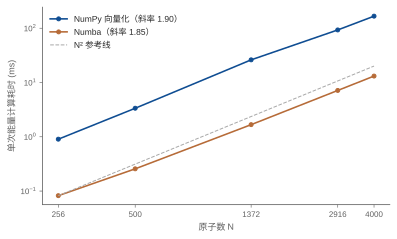

NumPy / Numba 耗时比： {256: 11.0, 500: 13.1, 1372: 15.6, 2916: 13.0, 4000: 12.7}


In [14]:
if njit is not None:
    cells = (4, 5, 7, 9, 10)  # N = 256 … 4000
    sizes = np.array([4 * m_cells**3 for m_cells in cells])
    t_np_n, t_nb_n = [], []
    for m_cells in cells:
        p, L = fcc_lattice(m_cells, 0.8, rng)
        t_np_n.append(best_time(lambda p=p, L=L: lj_energy_fast(p, L), number=1, repeat=3))
        t_nb_n.append(best_time(lambda p=p, L=L: lj_energy_numba(p, L), number=1, repeat=3))
    t_np_n, t_nb_n = np.array(t_np_n), np.array(t_nb_n)
    slope_np = np.polyfit(np.log(sizes), np.log(t_np_n), 1)[0]
    slope_nb = np.polyfit(np.log(sizes), np.log(t_nb_n), 1)[0]

    fig, ax = plt.subplots(figsize=(5.6, 3.4))
    ax.loglog(sizes, t_np_n * 1e3, "o-", color=BLUE, label=f"NumPy 向量化（斜率 {slope_np:.2f}）")
    ax.loglog(sizes, t_nb_n * 1e3, "o-", color=ORANGE, label=f"Numba（斜率 {slope_nb:.2f}）")
    ax.loglog(
        sizes,
        t_nb_n[0] * 1e3 * (sizes / sizes[0]) ** 2,
        ls="--",
        color=GRAY,
        lw=1,
        label="N² 参考线",
    )
    ax.set_xticks(sizes, labels=[str(s) for s in sizes])
    ax.minorticks_off()
    ax.set_xlabel("原子数 N")
    ax.set_ylabel("单次能量计算耗时 (ms)")
    ax.legend(fontsize=8.5)
    fig.tight_layout()
    plt.show()
    ratio = (t_np_n / t_nb_n).round(1)
    print("NumPy / Numba 耗时比：", dict(zip(sizes.tolist(), ratio.tolist(), strict=True)))

读法：两条线的斜率都接近 2，说明两者都是 $O(N^2)$ 算法，编译只改变常数，不改变复杂度。
把 $O(N^2)$ 变成 $O(N)$ 要靠算法（截断 + cell list），那是 M01.2 的内容；两者结合（Numba 写的 cell list）
才是生产级 MD 代码的做法。

## 小结

- 数组 = 内存块 + `shape`/`strides`；转置和基本切片是视图，花式索引是拷贝，用 `np.shares_memory` 判断。
- 在 Python 层按轴循环时，让循环轴对应连续内存；逐列访问 C 顺序数组会慢数倍。
- 广播把循环交给 C，速度提升两个数量级以上，但中间数组的内存随 $N^2$ 增长，峰值约为结果的两倍。
- `einsum` 在求和时直接累加，避免物化中间张量；多张量缩并打开 `optimize=True`。
- 预分配 `out=` 和原地运算消除临时数组，适合时间步循环。
- 先用 cProfile 找函数、line_profiler 找行，只改热点并验证结果不变。
- Numba 让朴素循环接近 C 的速度，有一次性的编译开销；它不改变算法复杂度。

可以尝试：把第 7 节的 `@njit` 换成 `@njit(parallel=True)` 并把外层 `range` 换成 `numba.prange`，
观察多核加速（注意 `energy +=` 的归约）；把第 3 节的密度调高，看截断内原子对的比例如何影响第 6 节的热点。